# Exercise 5: grouping and aggregating

The daily weather of 2023 at 13 KMI stations, `../../data/raw/kmi_daily_2023.csv`.

In [1]:
import pandas as pd

**5.1** Make one table with, per station, the mean temperature, the total rain, and the total hours of
sunshine (`sun_duration` is in minutes). Which station is the warmest, the wettest and the sunniest?

Docs: [`agg`](https://pandas.pydata.org/docs/reference/api/pandas.api.typing.DataFrameGroupBy.agg.html)

In [2]:
daily = pd.read_csv("../../data/raw/kmi_daily_2023.csv", parse_dates=["timestamp"])
per_station = daily.groupby("name").agg(
    mean_temp=("temp_avg", "mean"),
    rain_mm=("precip_quantity", "sum"),
    sun_minutes=("sun_duration", "sum"),
).assign(sun_hours=pd.col("sun_minutes") / 60)
per_station.sort_values("mean_temp")

,mean_temp,rain_mm,sun_minutes,sun_hours
name,,,,
MONT RIGI,8.374603,1934.54,100855.60,1680.926667
BUZENOL,10.565644,1437.27,100420.35,1673.672500
HUMAIN,10.868082,1007.81,116142.79,1935.713167
DOURBES,11.064411,948.54,105683.06,1761.384333
ERNAGE,11.566137,953.30,113976.96,1899.616000
RETIE,12.010658,1011.24,110779.73,1846.328833
DIEPENBEEK,12.050192,1026.65,116657.43,1944.290500
BEITEM,12.085370,987.88,120058.21,2000.970167
UCCLE,12.144137,1011.42,96618.98,1610.316333


Zeebrugge, on the coast, is the warmest, and also by far the driest. Mont Rigi, in the Ardennes, is the coldest and the wettest. Melle is the sunniest.

**5.2** Make a table with the mean temperature per month (rows) and station (columns). In which months
is it warmer at the coast (ZEEBRUGGE) than in Brussels (UCCLE)? Plot both
stations in one plot.

Docs: [`pivot_table`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pivot_table.html)

In [3]:
monthly = daily.assign(month=pd.col("timestamp").dt.month).pivot_table(
    index="month", columns="name", values="temp_avg", aggfunc="mean"
)
monthly[["ZEEBRUGGE", "UCCLE"]]

name,ZEEBRUGGE,UCCLE
month,,
1,6.853226,5.179355
2,6.769286,5.855714
3,7.881290,7.514194
4,9.309000,8.990333
5,12.837419,13.978387
6,18.192333,20.254333
7,18.419032,18.376774
8,18.308387,18.067097
9,19.192333,18.751000


<Axes: xlabel='month'>

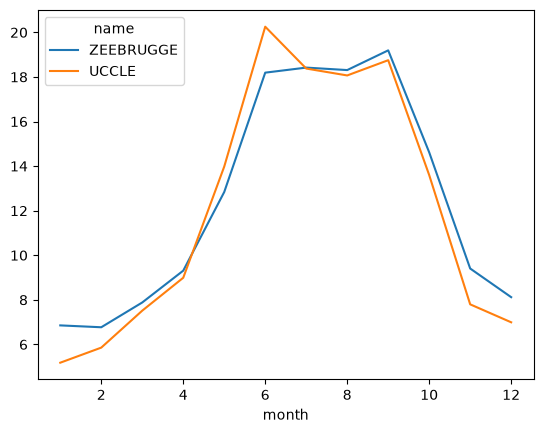

In [4]:
monthly[["ZEEBRUGGE", "UCCLE"]].plot()

In every month except May and June. The sea warms up slowly in spring, and cools down slowly in autumn and winter.

## Bonus

Count the frost days (lowest temperature below 0 °C) and the hot days (highest temperature 25 °C or more) of
every station, in one table.

In [5]:
frost_and_hot = (
    daily.assign(frost=pd.col("temp_min") < 0, hot=pd.col("temp_max") >= 25)
    .groupby("name")
    .agg(frost_days=("frost", "sum"), hot_days=("hot", "sum"))
)
frost_and_hot.sort_values("frost_days")

,frost_days,hot_days
name,,
ZEEBRUGGE,5,13
BEITEM,28,41
SINT-KATELIJNE-WAVER,30,44
UCCLE,30,44
STABROEK,33,41
MELLE,33,44
ERNAGE,37,44
RETIE,41,46
DIEPENBEEK,42,48
